In [1]:
import pandas as pd
import os

xls = pd.ExcelFile('data/servidores_gpu.xlsx')
print("Sheet names:", xls.sheet_names)
for sheet in xls.sheet_names:
    df = pd.read_excel('data/servidores_gpu.xlsx', sheet_name=sheet)
    print(f"\n--- Sheet: {sheet} (shape: {df.shape}) ---")
    print(df.head(10))
    print(df.info())

Sheet names: ['Sheet1']

--- Sheet: Sheet1 (shape: (53, 11)) ---
  Nome do responsável pela reserva Máquina@IP  Quantidade de GPUs  \
0                           User 1     Netuno                 1.0   
1                           User 2     Netuno                 1.0   
2                           User 2     Netuno                 1.0   
3                           User 3     Netuno                 1.0   
4                           User 2     Netuno                 1.0   
5                           User 3     Netuno                 1.0   
6                           User 2     Netuno                 1.0   
7                           User 1     Netuno                 1.0   
8                           User 4     Netuno                 1.0   
9                           User 1     Netuno                 1.0   

  Data e Hora de Início Data e Hora de Término Status da alocação  \
0        31/05/2025 14h         02/06/2025 10h          Concluído   
1        24/05/2025 16h         25/05

In [2]:
df = df[df["Data e Hora de Início"].notna() & df["Data e Hora de Término"].notna()]

In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 46 entries, 0 to 52
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   Nome do responsável pela reserva  46 non-null     str           
 1   Máquina@IP                        46 non-null     str           
 2   Quantidade de GPUs                42 non-null     float64       
 3   Data e Hora de Início             46 non-null     object        
 4   Data e Hora de Término            46 non-null     object        
 5   Status da alocação                45 non-null     str           
 6   Informou no canal do WhatsApp?    40 non-null     str           
 7   Observações                       10 non-null     str           
 8   inicio                            46 non-null     datetime64[us]
 9   termino                           46 non-null     datetime64[us]
 10  duracao_dias                      46 non-null     float64       
dty

In [4]:
import datetime
import re
import numpy as np
import pandas as pd

def parse_dt_corrigido(val):
    if pd.isna(val):
        return pd.NaT
    if isinstance(val, (pd.Timestamp, datetime.datetime, datetime.date, np.datetime64)):
        return pd.to_datetime(val)
    
    s = str(val).strip()
    # Cobre "DD/MM/YYYY HHh", "DD/MM/YYYY HHhMM" e "DD/MM/YYYY HH:MMh"
    m = re.match(r'^(\d{2}/\d{2}/\d{4})\s+(\d{1,2})[:h](\d{2})?h?$', s)
    if m:
        date_part, hour_part, min_part = m.groups()
        h = int(hour_part)
        mi = int(min_part) if min_part else 0
        dt = pd.to_datetime(date_part, format='%d/%m/%Y')
        return dt + pd.Timedelta(hours=h, minutes=mi)
        
    return pd.to_datetime(s, dayfirst=True, errors='coerce')

df['inicio'] = df['Data e Hora de Início'].apply(parse_dt_corrigido)
df['termino'] = df['Data e Hora de Término'].apply(parse_dt_corrigido)
df['duracao_dias'] = (df['termino'] - df['inicio']).dt.total_seconds() / 86400.0

print(df[['Nome do responsável pela reserva', 'Máquina@IP', 'Quantidade de GPUs', 'inicio', 'termino', 'duracao_dias', 'Status da alocação']].to_string())
print("\nResumo numérico de duração (dias):")
print(df['duracao_dias'].describe())
print("\nMáquinas:", df['Máquina@IP'].value_counts(dropna=False))
print("\nStatus:", df['Status da alocação'].value_counts(dropna=False))
print("\nWhatsApp:", df['Informou no canal do WhatsApp?'].value_counts(dropna=False))
print("\nUsuários únicos:", df['Nome do responsável pela reserva'].nunique())

   Nome do responsável pela reserva Máquina@IP  Quantidade de GPUs              inicio             termino  duracao_dias  Status da alocação
0                            User 1     Netuno                 1.0 2025-05-31 14:00:00 2025-06-02 10:00:00      1.833333           Concluído
1                            User 2     Netuno                 1.0 2025-05-24 16:00:00 2025-05-25 23:00:00      1.291667           Concluído
2                            User 2     Netuno                 1.0 2025-05-29 08:00:00 2025-05-30 13:00:00      1.208333           Concluído
3                            User 3     Netuno                 1.0 2025-06-03 22:00:00 2025-06-04 22:00:00      1.000000           Concluído
4                            User 2     Netuno                 1.0 2025-06-07 08:00:00 2025-06-08 23:00:00      1.625000           Concluído
5                            User 3     Netuno                 1.0 2025-06-13 14:00:00 2025-06-16 14:00:00      3.000000           Concluído
6            

In [5]:
df['Nome do responsável pela reserva'].value_counts()

Nome do responsável pela reserva
User 1     6
User 3     6
User 4     6
User 2     5
User 5     4
User 6     3
User 7     3
User 11    2
User 9     2
User 8     2
User 13    2
User 10    2
User 12    1
User 15    1
User 14    1
Name: count, dtype: int64

Usuários únicos normalizados: 15
usuario
User 1     6
User 3     6
User 4     6
User 2     5
User 5     4
User 6     3
User 7     3
User 11    2
User 9     2
User 8     2
User 13    2
User 10    2
User 12    1
User 15    1
User 14    1
Name: count, dtype: int64

Resumo Mensal:
         qtd_reservas  dias_reservados  media_duracao
mes                                                  
2025-05             3         4.333333       1.444444
2025-06             5         9.791667       1.958333
2025-07             2         4.666667       2.333333
2025-10             1         2.374306       2.374306
2025-11             6        16.440278       2.740046
2025-12             1         2.583333       2.583333
2026-01             1        31.000000      31.000000
2026-03             3        10.000000       3.333333
2026-04             1         5.000000       5.000000
2026-08             2        23.000000      11.500000
2026-09             3        14.000000       4.666667
2026-10             

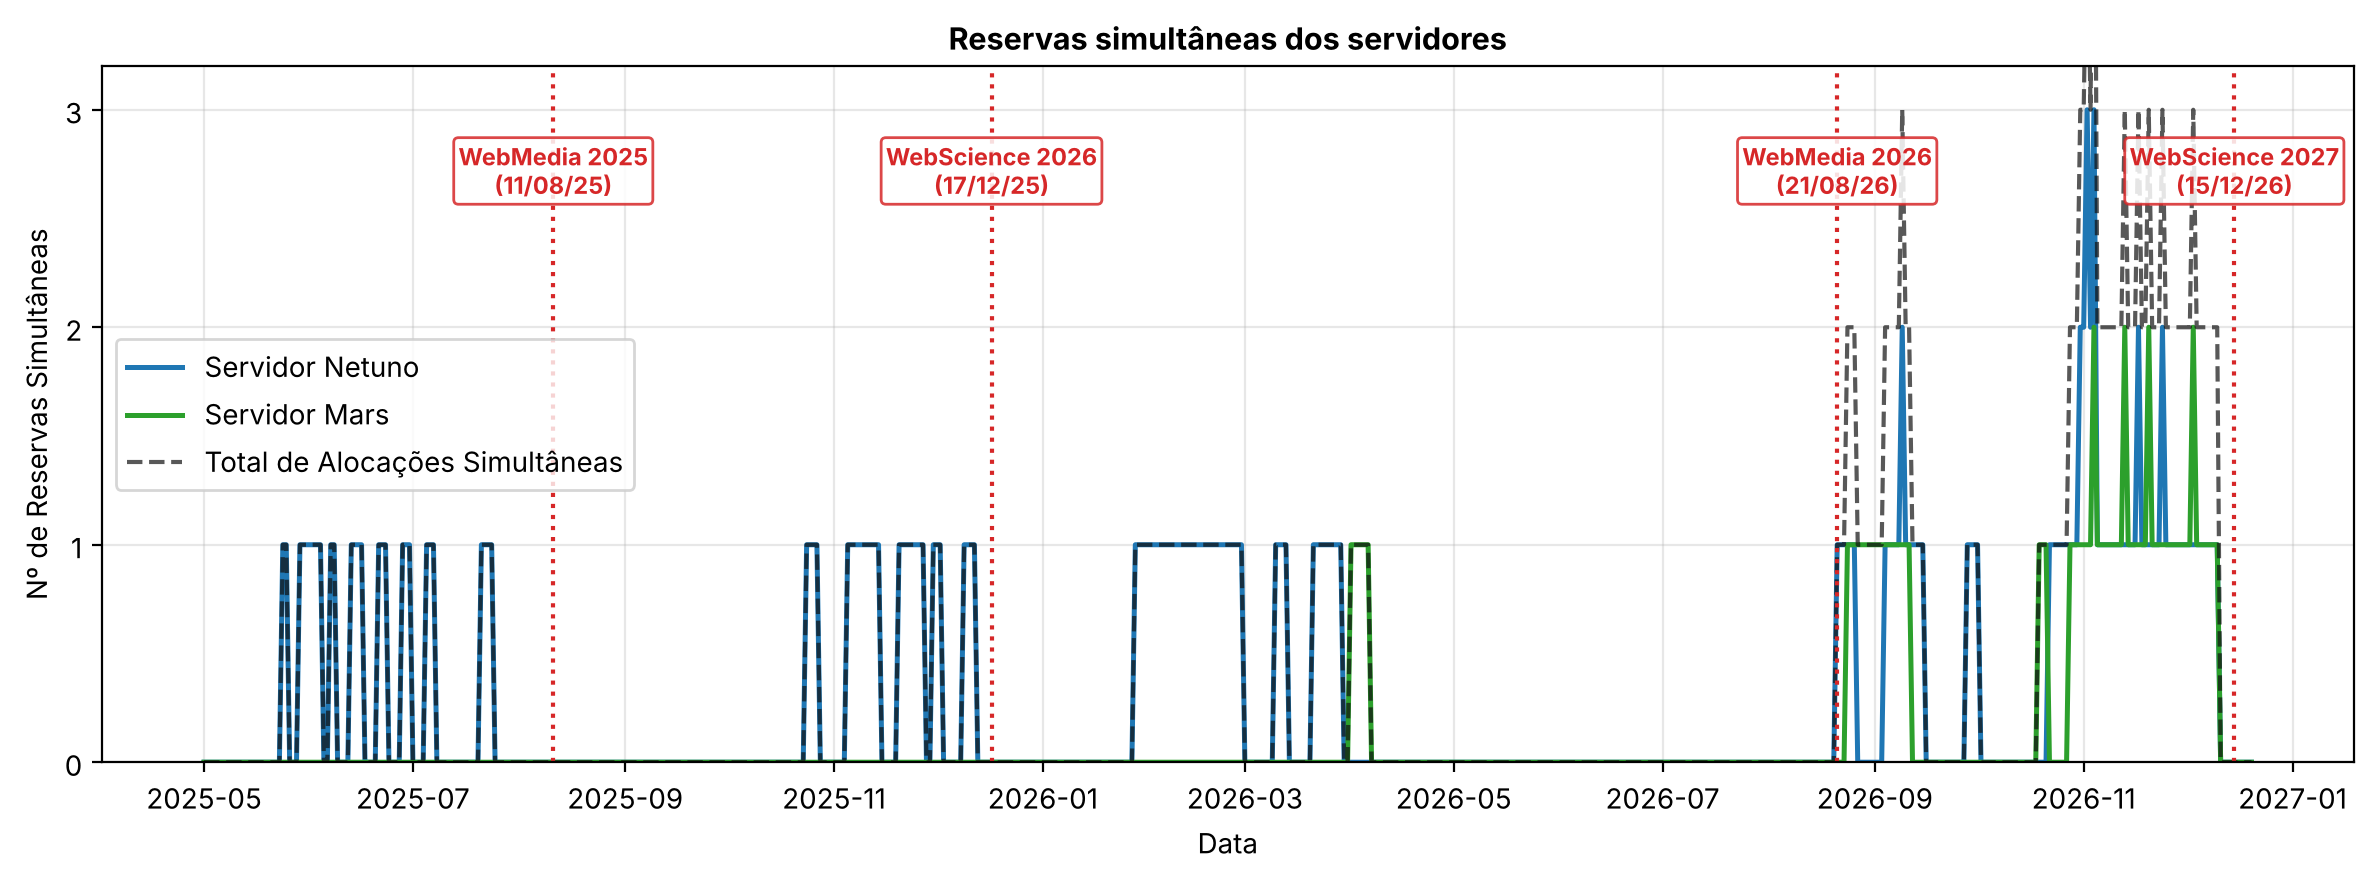

In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_clean = df.copy()

# Clean names for counting users properly
df_clean['usuario'] = df_clean['Nome do responsável pela reserva'].str.strip().replace({
    'Kenia Carolina': 'Kênia',
    'Flavio': 'Flávio Soriano'
})
print("Usuários únicos normalizados:", df_clean['usuario'].nunique())
print(df_clean['usuario'].value_counts())

# Filter valid dates
valid = df_clean.dropna(subset=['inicio']).copy()
valid['termino_est'] = valid['termino'].fillna(valid['inicio'] + pd.Timedelta(days=3))

# Create daily time series of concurrent reservations from May 2025 to Dec 2026
date_range = pd.date_range(start='2025-05-01', end='2026-12-20', freq='D')
ts = pd.DataFrame(index=date_range)
ts['reservas_ativas'] = 0
ts['netuno'] = 0
ts['mars'] = 0

for idx, row in valid.iterrows():
    if row['Status da alocação'] == 'Cancelado':
        continue
    mask = (ts.index >= row['inicio'].floor('D')) & (ts.index <= row['termino_est'].floor('D'))
    ts.loc[mask, 'reservas_ativas'] += 1
    if 'Netuno' in str(row['Máquina@IP']):
        ts.loc[mask, 'netuno'] += 1
    elif 'Mars' in str(row['Máquina@IP']):
        ts.loc[mask, 'mars'] += 1

# Monthly aggregation of started reservations and total reserved GPU-days
valid['mes'] = valid['inicio'].dt.to_period('M')
monthly = valid[valid['Status da alocação'] != 'Cancelado'].groupby('mes').agg(
    qtd_reservas=('usuario', 'count'),
    dias_reservados=('duracao_dias', 'sum'),
    media_duracao=('duracao_dias', 'mean')
)
print("\nResumo Mensal:")
print(monthly.to_string())

# Deadlines
deadlines = {
    'WebMedia 2025\n(11/08/25)': pd.Timestamp('2025-08-11'),
    'WebScience 2026\n(17/12/25)': pd.Timestamp('2025-12-17'),
    'WebMedia 2026\n(21/08/26)': pd.Timestamp('2026-08-21'),
    'WebScience 2027\n(15/12/26)': pd.Timestamp('2026-12-15'),
}

# Check activity 30 days before each deadline vs outside
for name, d in deadlines.items():
    win_start = d - pd.Timedelta(days=30)
    in_win = valid[(valid['inicio'] > win_start) & (valid['inicio'] < d)]
    print(f"\nJanela 30d antes de {name.replace(chr(10), ' ')}: {len(in_win)} reservas iniciadas")
    if len(in_win) > 0:
        print(in_win[['usuario', 'Máquina@IP', 'inicio', 'termino', 'duracao_dias', 'Status da alocação']])

# Plot time series
plt.figure(figsize=(12, 4.5))
plt.plot(ts.index, ts['netuno'], label='Servidor Netuno', color='#1f77b4', linewidth=1.8)
plt.plot(ts.index, ts['mars'], label='Servidor Mars', color='#2ca02c', linewidth=1.8)
plt.plot(ts.index, ts['reservas_ativas'], label='Total de Alocações Simultâneas', color='#111111', linestyle='--', alpha=0.7)

for label, dt in deadlines.items():
    plt.axvline(dt, color='#d62728', linestyle=':', linewidth=1.5)
    plt.text(dt, 2.85, label, color='#d62728', fontsize=8.5, ha='center', va='top', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#d62728', alpha=0.85))

plt.title('Reservas simultâneas dos servidores', fontsize=11, fontweight='bold')
plt.ylabel('Nº de Reservas Simultâneas')
plt.xlabel('Data')
plt.ylim(0, 3.2)
plt.yticks([0, 1, 2, 3])
plt.grid(True, alpha=0.3)
plt.legend(loc="center left")
plt.tight_layout()
plt.savefig('images/comportamento_temporal_gpu.pdf')

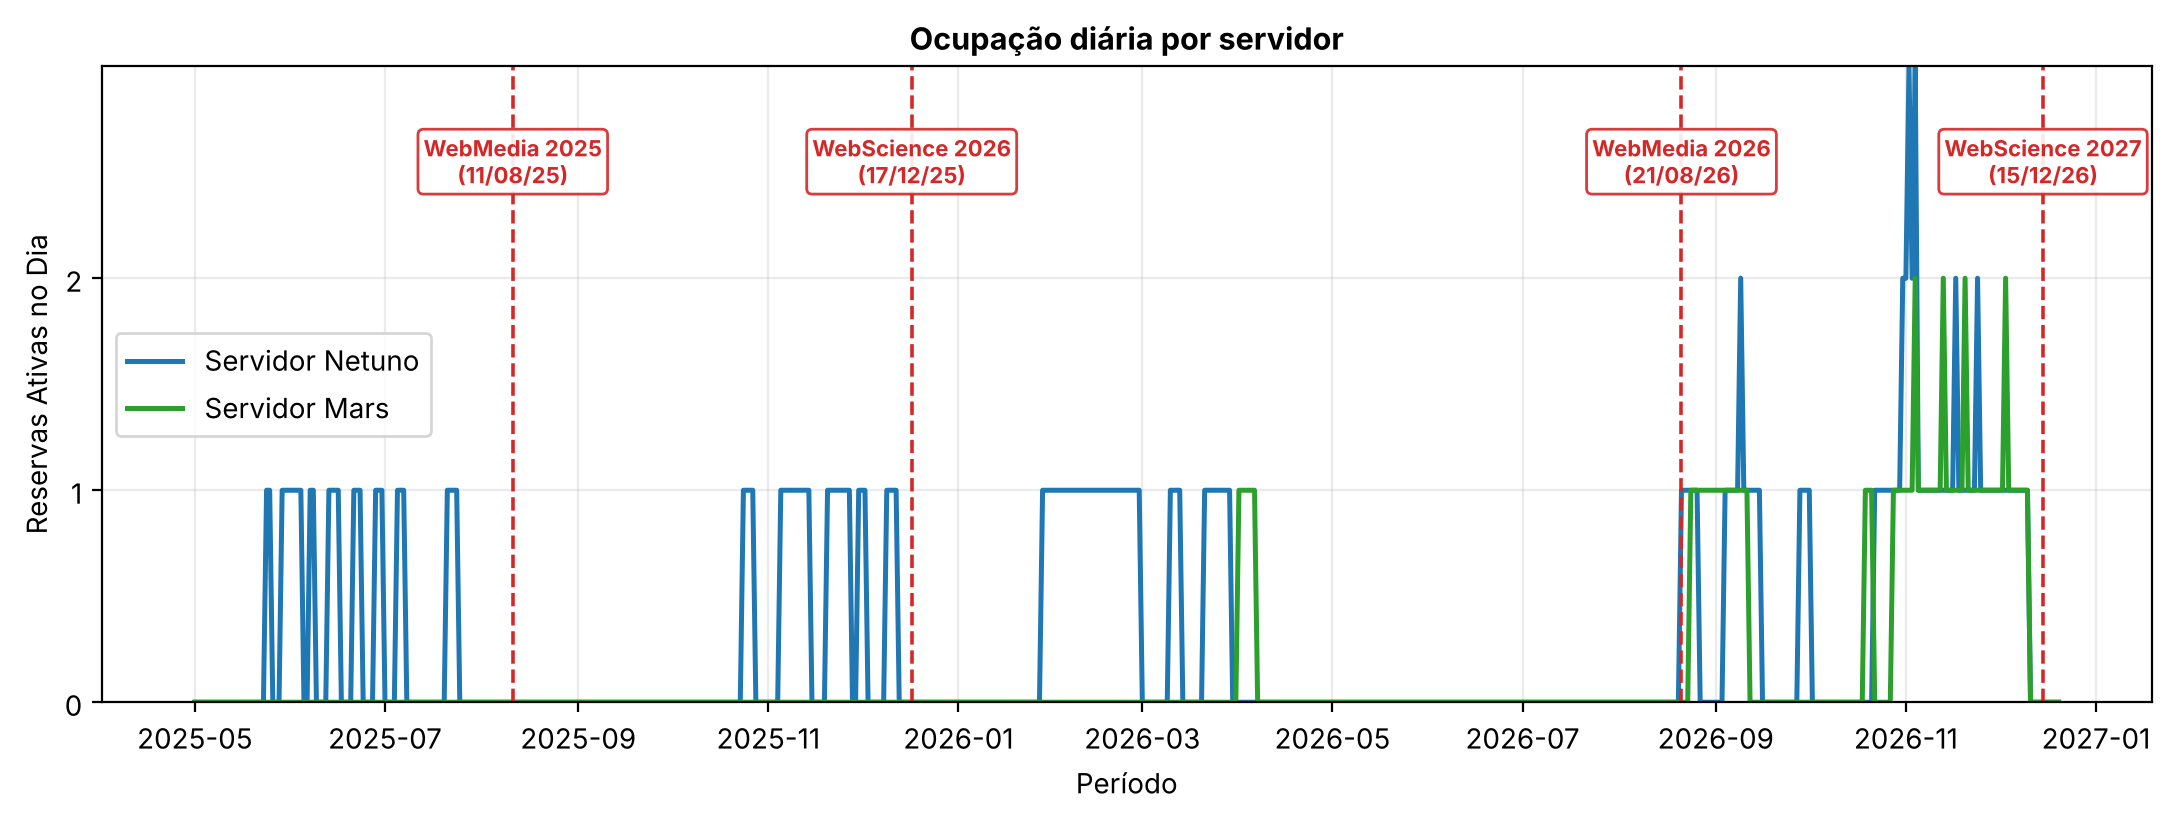

In [7]:
plt.figure(figsize=(11, 4.2))
plt.plot(ts.index, ts['netuno'], label='Servidor Netuno', color='#1f77b4', linewidth=1.8)
plt.plot(ts.index, ts['mars'], label='Servidor Mars', color='#2ca02c', linewidth=1.8)

deadlines_clean = [
    ('WebMedia 2025\n(11/08/25)', pd.Timestamp('2025-08-11'), 2.55),
    ('WebScience 2026\n(17/12/25)', pd.Timestamp('2025-12-17'), 2.55),
    ('WebMedia 2026\n(21/08/26)', pd.Timestamp('2026-08-21'), 2.55),
    ('WebScience 2027\n(15/12/26)', pd.Timestamp('2026-12-15'), 2.55),
]

for label, dt, y_pos in deadlines_clean:
    plt.axvline(dt, color='#d62728', linestyle='--', linewidth=1.3)
    plt.text(dt, y_pos, label, color='#d62728', fontsize=8, ha='center', va='center', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#d62728', alpha=0.9))

plt.title('Ocupação diária por servidor', fontsize=11, fontweight='bold')
plt.ylabel('Reservas Ativas no Dia')
plt.xlabel('Período')
plt.ylim(0, 3.0)
plt.yticks([0, 1, 2])
plt.grid(True, alpha=0.25)
plt.legend(loc="center left")
plt.tight_layout()
plt.savefig('images/ocupacao_servidores_gpu.pdf')

In [8]:
# ============================================================
# Modelo DEF em tempo discreto (passo = 1 dia)
# Estoques: Q = fila de espera | G = GPUs ocupadas | E = GPU-dia de reserva precaucionária
# Fluxos:   A = chegadas | S = inícios | R = liberações
# Calibrado nos dados: LAMBDA (chegadas/dia) e DBAR (duração média)
# HIPÓTESES (não medidas; a planilha não informa): K (GPUs por servidor) e ALPHA
# (quanto a reserva precaucionária estica a duração perto de um prazo)
# ============================================================
import numpy as np

ok = valid[valid['Status da alocação'] != 'Cancelado'].copy()
PERIODO = (ok['inicio'].max() - ok['inicio'].min()).days + 1
LAMBDA = len(ok) / PERIODO
DBAR = ok['duracao_dias'].mean()
N_SERVIDORES = 2
K_BASE = 2          # hipótese: 2 GPUs por servidor
ALPHA_BASE = 0.5    # hipótese: +50% de duração quando há pressão de prazo
JANELA = 30         # dias antes de um prazo em que a pressão está ativa
PRAZOS = [pd.Timestamp(d) for d in ['2025-08-11', '2025-12-17', '2026-08-21', '2026-12-15']]

print(f"Chegadas calibradas: {LAMBDA:.3f} reservas/dia ({len(ok)} reservas em {PERIODO} dias)")
print(f"Duração média calibrada: {DBAR:.2f} dias")
print(f"Carga média λ·d̄ = {LAMBDA * DBAR:.2f} GPUs")


def pressao(dia, janela=JANELA):
    """1.0 se algum prazo cai nos próximos `janela` dias, senão 0.0."""
    return float(any(0 <= (p - dia).days <= janela for p in PRAZOS))


def simular_def(dias, chegadas, K=K_BASE, alpha=ALPHA_BASE, dbar=DBAR, janela=JANELA, gamma=0.0):
    """Integra o modelo dia a dia: x(t) = F(x(t-1)). `chegadas` tem o mesmo tamanho de `dias`.
    gamma = 0 reproduz a versão original (pressão só pelo calendário)."""
    C = K * N_SERVIDORES
    Q, G, E = 0.0, 0.0, 0.0
    out = []
    for dia, A in zip(dias, chegadas):
        p = min(1.0, pressao(dia, janela) + gamma * Q)  # gamma>0: a fila também gera pressão (laço R do DLC)
        R = G / (dbar * (1 + alpha * p))      # liberações do dia
        livre = max(C - (G - R), 0.0)         # GPUs livres ao fim do dia
        S = min(Q + A, livre)                 # inícios do dia, limitados pela capacidade
        out.append((dia, Q, G, E, A, S, R, p, C))
        Q = Q + A - S
        G = G + S - R
        E = E + G * alpha * p                 # GPU-dia extra acumulado por precaução
    return pd.DataFrame(out, columns=['dia', 'Q', 'G', 'E', 'A', 'S', 'R', 'p', 'C']).set_index('dia')


DIAS = ts.index
OBS = ts['reservas_ativas'].astype(float)
CHEG_MEDIA = np.full(len(DIAS), LAMBDA)


def monte_carlo(K, alpha, lam=LAMBDA, reps=200, seed=42):
    """Chegadas Poisson(λ) por dia; repete `reps` vezes e resume a fila e a ocupação."""
    rng = np.random.default_rng(seed)
    res = []
    for _ in range(reps):
        sim = simular_def(DIAS, rng.poisson(lam, size=len(DIAS)), K=K, alpha=alpha)
        res.append((sim['Q'].max(), sim['G'].mean()))
    r = np.array(res)
    return {'fila_max_media': r[:, 0].mean(),
            'fila_max_p95': np.percentile(r[:, 0], 95),
            'ocupacao_media': r[:, 1].mean()}


def equilibrio(K, alpha, p, lam=LAMBDA):
    """Ponto de equilíbrio G* = λ·d̄·(1+αp) comparado à capacidade C = K·servidores."""
    C = K * N_SERVIDORES
    g = lam * DBAR * (1 + alpha * p)
    return g, C, ('estável' if g < C else 'instável (fila cresce)')

Chegadas calibradas: 0.081 reservas/dia (45 reservas em 559 dias)
Duração média calibrada: 4.82 dias
Carga média λ·d̄ = 0.39 GPUs


Erro médio absoluto (GPUs ocupadas vs proxy observado): 0.583


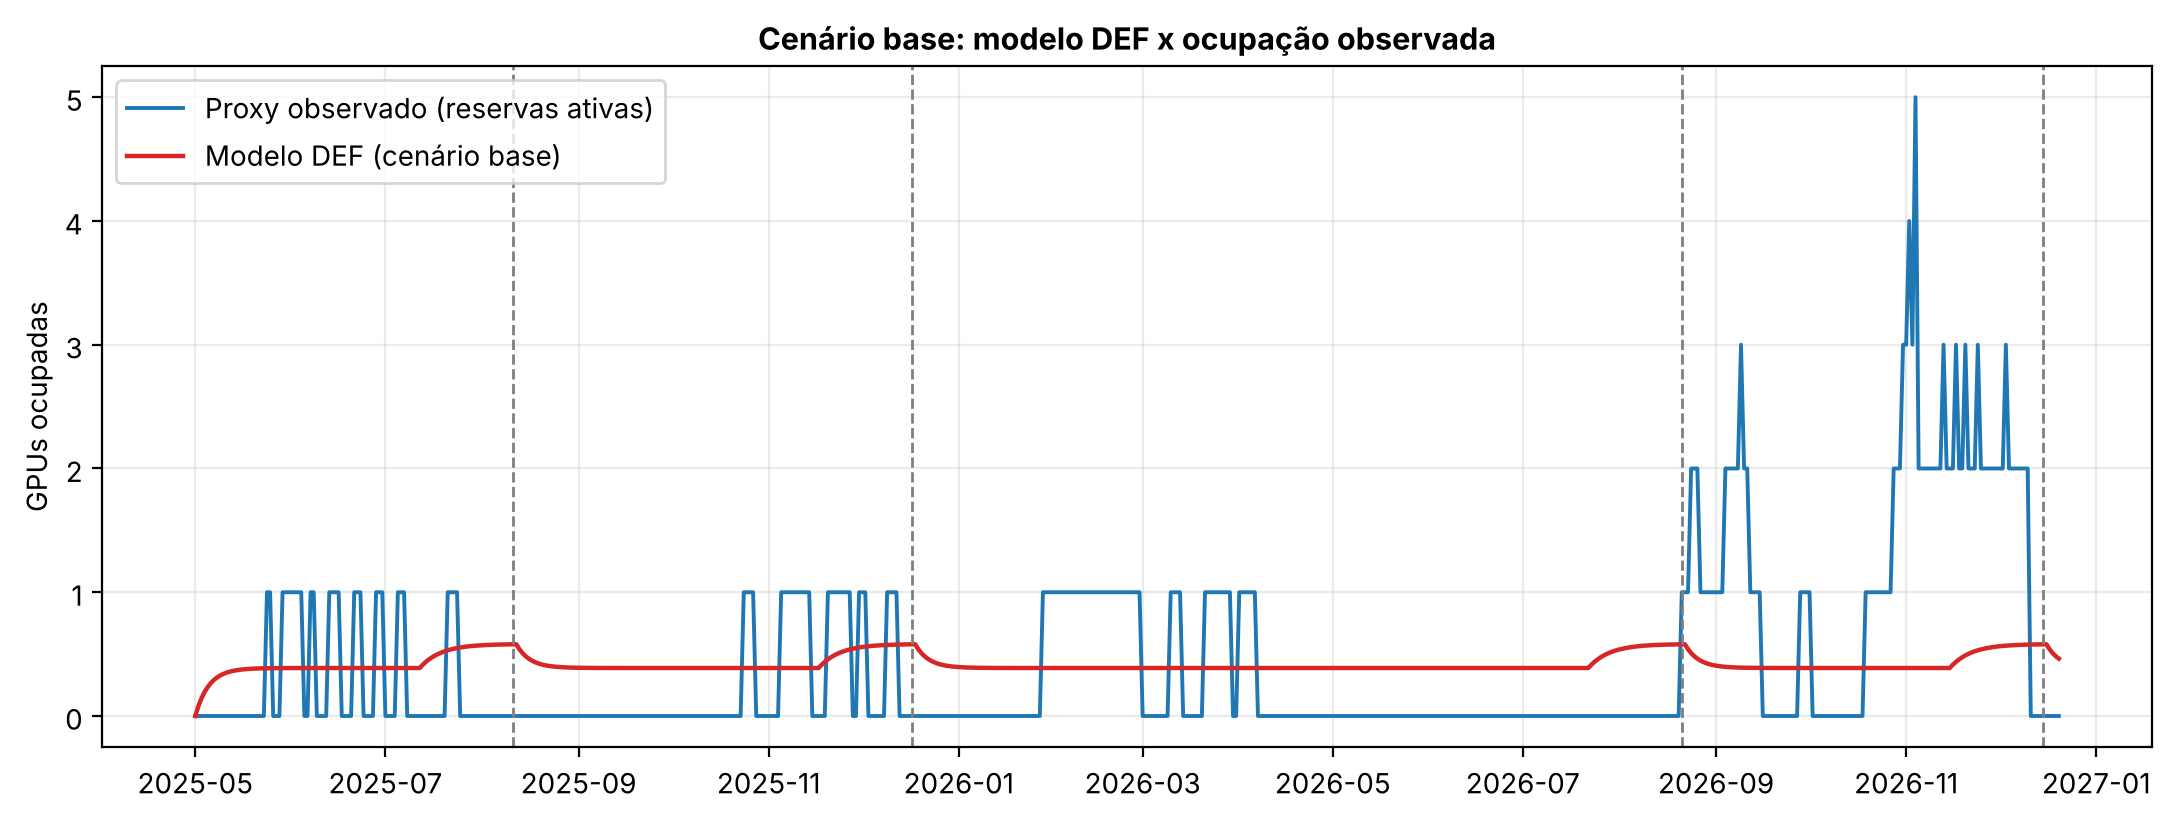

                        fila_max_media  fila_max_p95  ocupacao_media
Base                              0.00          0.00            0.42
Sem precaução (α=0)               0.00          0.00            0.39
Capacidade baixa (K=1)            0.77          1.66            0.42
Carga x3                          0.80          2.43            1.26
               cenário      regime   G*  capacidade C  status
                  Base sem pressão 0.39             4 estável
                  Base com pressão 0.58             4 estável
   Sem precaução (α=0) sem pressão 0.39             4 estável
   Sem precaução (α=0) com pressão 0.39             4 estável
Capacidade baixa (K=1) sem pressão 0.39             2 estável
Capacidade baixa (K=1) com pressão 0.58             2 estável
              Carga x3 sem pressão 1.16             4 estável
              Carga x3 com pressão 1.75             4 estável


 K  alpha  fila_max_media  fila_max_p95
 1    0.0            0.64          1.48
 1    0.5            0.76          1.52
 1    1.0            0.90          1.66
 2    0.0            0.00          0.00
 2    0.5            0.00          0.00
 2    1.0            0.01          0.00
 3    0.0            0.00          0.00
 3    0.5            0.00          0.00
 3    1.0            0.00          0.00
 4    0.0            0.00          0.00
 4    0.5            0.00          0.00
 4    1.0            0.00          0.00


In [9]:
# --- Cenário base: reprodução da ocupação observada (proxy) ---
base = simular_def(DIAS, CHEG_MEDIA, K=K_BASE, alpha=ALPHA_BASE)
mae = float(np.mean(np.abs(base['G'].values - OBS.values)))
print(f"Erro médio absoluto (GPUs ocupadas vs proxy observado): {mae:.3f}")

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(DIAS, OBS.values, color='#1f77b4', linewidth=1.4, label='Proxy observado (reservas ativas)')
ax.plot(DIAS, base['G'].values, color='#d62728', linewidth=1.6, label='Modelo DEF (cenário base)')
for p in PRAZOS:
    ax.axvline(p, color='#7f7f7f', linestyle='--', linewidth=1)
ax.set_title('Cenário base: modelo DEF x ocupação observada', fontsize=11, fontweight='bold')
ax.set_ylabel('GPUs ocupadas')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('images/simulacao_def_cenario_base.pdf')
plt.show()

# --- Cenários ---
cenarios = {
    'Base': dict(K=K_BASE, alpha=ALPHA_BASE, lam=LAMBDA),
    'Sem precaução (α=0)': dict(K=K_BASE, alpha=0.0, lam=LAMBDA),
    'Capacidade baixa (K=1)': dict(K=1, alpha=ALPHA_BASE, lam=LAMBDA),
    'Carga x3': dict(K=K_BASE, alpha=ALPHA_BASE, lam=3 * LAMBDA),
}
tab = pd.DataFrame({nome: monte_carlo(**c) for nome, c in cenarios.items()}).T
tab.to_csv('data/resultados_cenarios.csv')
print(tab.round(2).to_string())

# --- Equilíbrios analíticos ---
eq = []
for nome, c in cenarios.items():
    for p in (0.0, 1.0):
        g, C, status = equilibrio(c['K'], c['alpha'], p, lam=c['lam'])
        eq.append((nome, 'com pressão' if p else 'sem pressão', round(g, 2), C, status))
print(pd.DataFrame(eq, columns=['cenário', 'regime', 'G*', 'capacidade C', 'status']).to_string(index=False))

# --- Sensibilidade: capacidade K x intensidade da precaução α ---
sens = []
for K in (1, 2, 3, 4):
    for alpha in (0.0, 0.5, 1.0):
        m = monte_carlo(K, alpha, reps=100)
        sens.append((K, alpha, m['fila_max_media'], m['fila_max_p95']))
sens = pd.DataFrame(sens, columns=['K', 'alpha', 'fila_max_media', 'fila_max_p95'])
print(sens.round(2).to_string(index=False))

## Extensão: capacidade efetiva, pressão nas chegadas e pico de nov/2026
Usa as mesmas funções do modelo acima. Responde às pendências: (2) capacidade por servidor,
(3) laço fila → pressão (`gamma`), (6) sensibilidade a λ, d̄ e janela, e mede a ocupação pelas horas reservadas.

In [10]:
# --- 1) Ocupação pelas horas reservadas (não conta 2x o dia em que uma reserva termina e outra começa)
horas = pd.date_range(DIAS[0], DIAS[-1] + pd.Timedelta(hours=23), freq='h')
occ = pd.DataFrame(0.0, index=horas, columns=['Netuno', 'Mars'])
for _, r in ok.iterrows():
    serv = 'Netuno' if 'Netuno' in str(r['Máquina@IP']) else 'Mars'
    occ.loc[(horas >= r['inicio']) & (horas < r['termino']), serv] += 1
for s in occ:
    print(f"{s}: {(occ[s] >= 2).sum()} h com 2 reservas simultâneas, de {(occ[s] >= 1).sum()} h ocupadas")
OBS_H = occ.resample('D').mean().reindex(DIAS).fillna(0)
OBS_H['total'] = OBS_H.sum(axis=1)
NOV = (DIAS >= '2026-11-01') & (DIAS <= '2026-12-09')
print(f"Ocupação média: {OBS_H.total.mean():.2f} GPU | pico diário: {OBS_H.total.max():.2f} | "
      f"01/11-09/12/2026: {OBS_H.total[NOV].mean():.2f} GPU")

# --- 2) A pressão muda as chegadas (beta) ou a duração (alpha)? Calibração para várias janelas
def calibrar(janela):
    p = np.array([pressao(d, janela) for d in DIAS])
    dentro = ok['inicio'].dt.floor('D').map(lambda d: pressao(d, janela) == 1).values
    lam_out, lam_in = (~dentro).sum() / (p == 0).sum(), dentro.sum() / p.sum()
    alpha = ok['duracao_dias'][dentro].mean() / ok['duracao_dias'][~dentro].mean() - 1
    return p, lam_out, lam_in / lam_out - 1, alpha

for j in (15, 30, 45, 60):
    _, l0, b, a = calibrar(j)
    print(f"janela {j:2d} d: lambda0 = {l0:.3f}/dia  beta = {b:+.2f}  alpha = {a:+.2f}")
P30, LAMBDA0, BETA, ALPHA_DADOS = calibrar(JANELA)

# --- 3) Pico de out-dez/2026
pico = ok[(ok['inicio'] >= '2026-10-15') & (ok['inicio'] < '2026-12-15')]
LAM_PICO, DBAR_PICO = len(pico) / 61, pico['duracao_dias'].mean()
print(f"Pico: {len(pico)} reservas em 61 dias -> lambda = {LAM_PICO:.3f}/dia, d = {DBAR_PICO:.2f} d, "
      f"carga = {LAM_PICO * DBAR_PICO:.2f} GPU")

Netuno: 72 h com 2 reservas simultâneas, de 3508 h ocupadas
Mars: 0 h com 2 reservas simultâneas, de 1622 h ocupadas
Ocupação média: 0.36 GPU | pico diário: 3.00 | 01/11-09/12/2026: 1.97 GPU
janela 15 d: lambda0 = 0.077/dia  beta = -0.18  alpha = +0.08
janela 30 d: lambda0 = 0.069/dia  beta = +0.39  alpha = +0.03
janela 45 d: lambda0 = 0.051/dia  beta = +1.58  alpha = -0.16
janela 60 d: lambda0 = 0.039/dia  beta = +2.22  alpha = -0.30
Pico: 17 reservas em 61 dias -> lambda = 0.279/dia, d = 5.50 d, carga = 1.53 GPU


In [11]:
def mc(lam_t, K, alpha=0.0, dbar=DBAR, gamma=0.0, reps=200, seed=42):
    """Monte Carlo com taxa de chegada por dia (lam_t: escalar ou vetor). Espera média por Little."""
    lam_t = np.broadcast_to(lam_t, len(DIAS)).astype(float)
    rng = np.random.default_rng(seed)
    Qm, Qx, Gm, Qs, Gs = [], [], [], [], []
    for _ in range(reps):
        sim = simular_def(DIAS, rng.poisson(lam_t), K=K, alpha=alpha, dbar=dbar, gamma=gamma)
        Qm.append(sim['Q'].mean()); Qx.append(sim['Q'].max()); Gm.append(sim['G'].mean())
        Qs.append(sim['Q'].values); Gs.append(sim['G'].values)
    lam = lam_t.mean()
    return dict(rho=lam * dbar / (K * N_SERVIDORES), ocup=np.mean(Gm), fila_max=np.mean(Qx),
                fila_p95=np.percentile(Qx, 95), espera=np.mean(Qm) / lam, pior=np.mean(Qx) / lam,
                Q=np.array(Qs), G=np.array(Gs))

lam_base = LAMBDA0 * (1 + BETA * P30)          # pressão agindo nas chegadas, calibrada nos dados
cen = {
    'Base, K=2 (hipótese original)':  dict(lam_t=lam_base, K=2, alpha=ALPHA_DADOS),
    'Base, K=1 (uso exclusivo)':      dict(lam_t=lam_base, K=1, alpha=ALPHA_DADOS),
    'Base, K=1, alpha=1':             dict(lam_t=lam_base, K=1, alpha=1.0),
    'Pico nov/26, K=2':               dict(lam_t=LAM_PICO, K=2, dbar=DBAR_PICO),
    'Pico nov/26, K=1':               dict(lam_t=LAM_PICO, K=1, dbar=DBAR_PICO),
    'Pico, K=1, fila->pressão (a=g=0,5)': dict(lam_t=LAM_PICO, K=1, dbar=DBAR_PICO, alpha=0.5, gamma=0.5),
    'Pico, K=1, teto de 4 dias':      dict(lam_t=LAM_PICO, K=1, dbar=4.0),
    'Carga x7, K=1':                  dict(lam_t=7 * lam_base, K=1, alpha=ALPHA_DADOS),
}
res = {n: mc(**c) for n, c in cen.items()}
tab2 = pd.DataFrame({n: {k: v for k, v in r.items() if k not in ('Q', 'G')} for n, r in res.items()}).T
tab2.to_csv('data/resultados_cenarios_v2.csv')
print(tab2.round(2).to_string())

print("\nEquilíbrio G* = lambda0(1+beta p) d (1+alpha p):",
      [round(LAMBDA0 * (1 + BETA * p) * DBAR * (1 + ALPHA_DADOS * p), 2) for p in (0, 1)], "GPU")

# Sensibilidade no pico (K=1)
sens = {'referência': {}, 'd -20%': dict(dbar=0.8 * DBAR_PICO), 'd +20%': dict(dbar=1.2 * DBAR_PICO),
        'lambda -20%': dict(lam_t=0.8 * LAM_PICO), 'lambda +20%': dict(lam_t=1.2 * LAM_PICO),
        'alpha=0,5': dict(alpha=0.5), 'alpha=gamma=0,5': dict(alpha=0.5, gamma=0.5)}
tab3 = pd.DataFrame({n: {k: v for k, v in mc(**{**dict(lam_t=LAM_PICO, K=1, dbar=DBAR_PICO), **kw}).items()
                         if k in ('rho', 'espera', 'fila_max')} for n, kw in sens.items()}).T
print(tab3.round(2).to_string())

                                     rho  ocup  fila_max  fila_p95  espera    pior
Base, K=2 (hipótese original)       0.09  0.36      0.00      0.00    0.00    0.00
Base, K=1 (uso exclusivo)           0.18  0.36      0.58      1.61    0.04    7.66
Base, K=1, alpha=1                  0.18  0.44      0.94      2.19    0.14   12.55
Pico nov/26, K=2                    0.38  1.52      1.22      2.41    0.03    4.39
Pico nov/26, K=1                    0.77  1.51      6.48     10.64    3.51   23.24
Pico, K=1, fila->pressão (a=g=0,5)  0.77  1.88     25.49     45.35   42.47   91.47
Pico, K=1, teto de 4 dias           0.56  1.11      3.55      5.40    0.71   12.74
Carga x7, K=1                       1.27  1.97     70.87     99.81   63.62  134.76

Equilíbrio G* = lambda0(1+beta p) d (1+alpha p): [np.float64(0.33), np.float64(0.48)] GPU


                  rho  fila_max  espera
referência       0.77      6.48    3.51
d -20%           0.61      4.16    1.08
d +20%           0.92     10.97   12.23
lambda -20%      0.61      3.71    1.21
lambda +20%      0.92     11.93   10.62
alpha=0,5        0.77      8.26    5.78
alpha=gamma=0,5  0.77     25.49   42.47


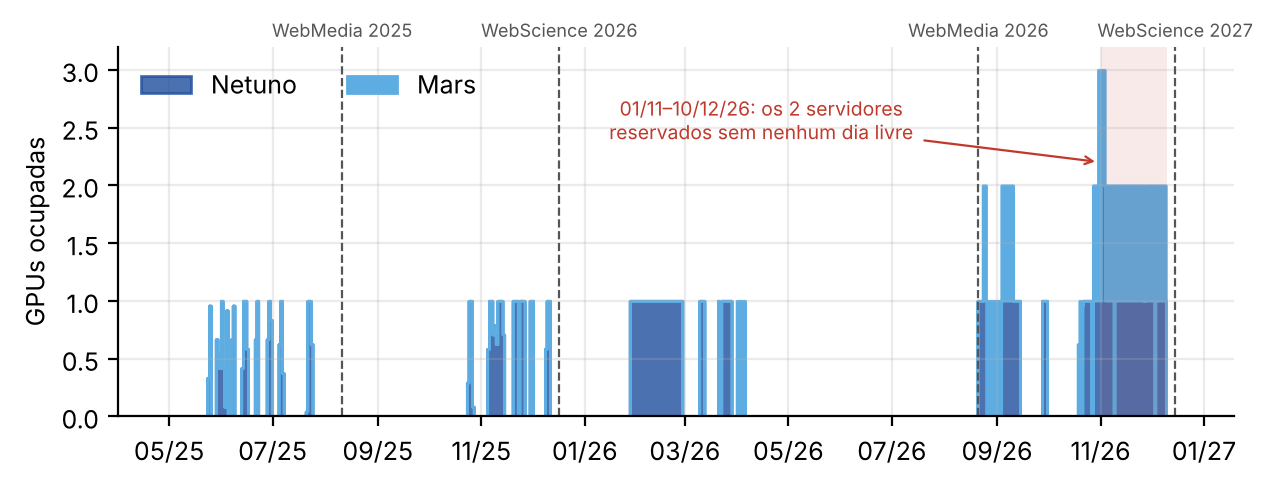

Histórico K=2: MAE = 0.35 GPU, fila máx. média = 0.20, pior dia (média) = 0.04
Histórico K=1: MAE = 0.36 GPU, fila máx. média = 2.36, pior dia (média) = 1.05


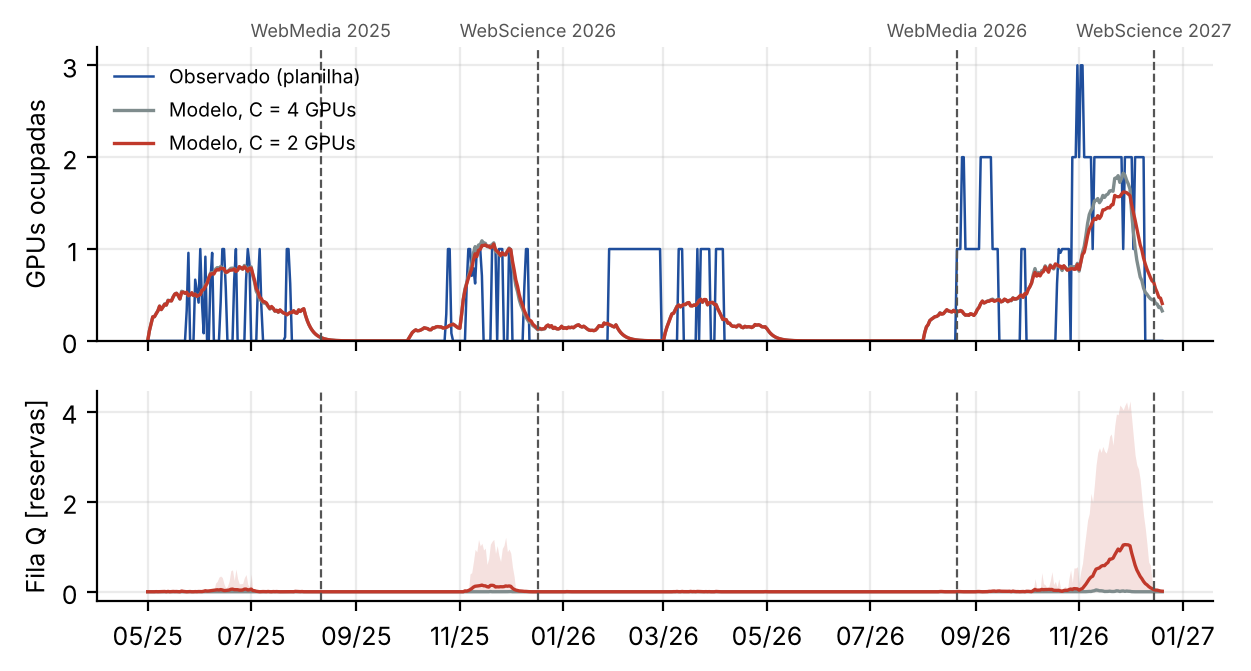

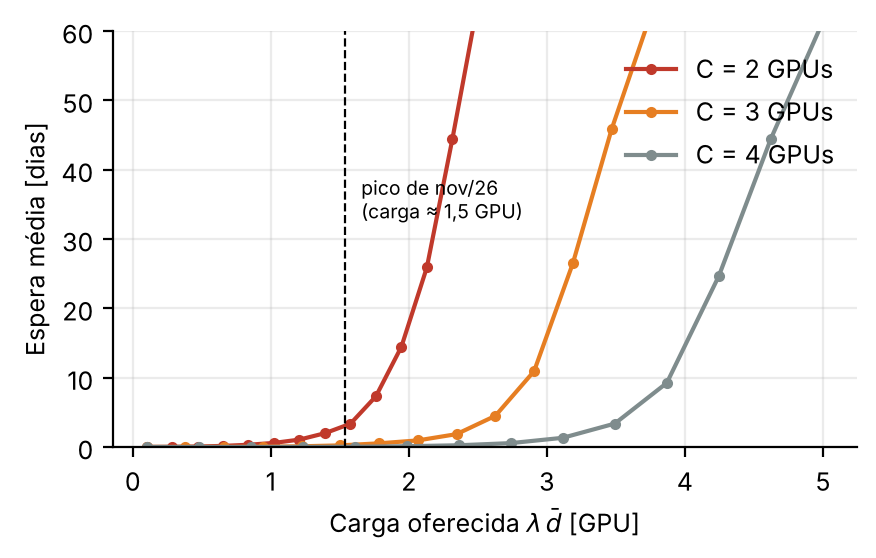

In [12]:
# --- Figuras do relatório
def deadlines(ax, rotulo=True):
    nomes = ['WebMedia 2025', 'WebScience 2026', 'WebMedia 2026', 'WebScience 2027']
    for nome, d in zip(nomes, PRAZOS):
        ax.axvline(d, color='#555', ls='--', lw=0.8)
        if rotulo:
            ax.annotate(nome, (d, 1), xycoords=('data', 'axes fraction'), xytext=(0, 2),
                        textcoords='offset points', ha='center', va='bottom', fontsize=6.5, color='#555')

plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
fmt = mdates.DateFormatter('%m/%y')

# (a) ocupação observada por servidor
fig, ax = plt.subplots(figsize=(7.2, 2.4))
ax.fill_between(DIAS, 0, OBS_H.Netuno, step='mid', color='#1f4e9c', alpha=.8, label='Netuno')
ax.fill_between(DIAS, OBS_H.Netuno, OBS_H.total, step='mid', color='#5dade2', label='Mars')
ax.axvspan(pd.Timestamp('2026-11-01'), pd.Timestamp('2026-12-10'), color='#c0392b', alpha=.1, lw=0)
ax.annotate('01/11–10/12/26: os 2 servidores\nreservados sem nenhum dia livre', (pd.Timestamp('2026-11-01'), 2.2),
            xytext=(pd.Timestamp('2026-04-15'), 2.4), fontsize=7, color='#c0392b', ha='center',
            arrowprops=dict(arrowstyle='->', color='#c0392b', lw=.8))
ax.set_ylim(0, 3.2); ax.set_ylabel('GPUs ocupadas'); ax.grid(alpha=.25); ax.xaxis.set_major_formatter(fmt)
ax.legend(loc='upper left', frameon=False, ncol=2); deadlines(ax)
fig.savefig('images/ocupacao_observada.pdf', bbox_inches='tight'); plt.show()

# (b) histórico: chegadas mensais observadas, K=2 x K=1
mes = ok.groupby(ok['inicio'].dt.to_period('M')).size()
lam_mes = np.array([mes.get(m, 0) / m.days_in_month for m in DIAS.to_period('M')])
hist = {K: mc(lam_mes, K=K, alpha=ALPHA_DADOS) for K in (2, 1)}
for K, r in hist.items():
    print(f"Histórico K={K}: MAE = {np.abs(r['G'].mean(0) - OBS_H.total.values).mean():.2f} GPU, "
          f"fila máx. média = {r['fila_max']:.2f}, pior dia (média) = {r['Q'].mean(0).max():.2f}")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 3.6), sharex=True, height_ratios=[1.4, 1])
a1.plot(DIAS, OBS_H.total, color='#1f4e9c', lw=.9, label='Observado (planilha)')
for K, cor in ((2, '#7f8c8d'), (1, '#c0392b')):
    a1.plot(DIAS, hist[K]['G'].mean(0), color=cor, lw=1.2, label=f'Modelo, C = {2*K} GPUs')
    a2.plot(DIAS, hist[K]['Q'].mean(0), color=cor, lw=1.2)
    lo, hi = np.percentile(hist[K]['Q'], [5, 95], axis=0); a2.fill_between(DIAS, lo, hi, color=cor, alpha=.15, lw=0)
a1.set_ylim(0, 3.2); a1.set_ylabel('GPUs ocupadas'); a1.legend(frameon=False, fontsize=7, loc='upper left')
a2.set_ylabel('Fila Q [reservas]'); a2.xaxis.set_major_formatter(fmt)
for a in (a1, a2): a.grid(alpha=.25)
deadlines(a1); deadlines(a2, False)
fig.savefig('images/cenario_historico.pdf', bbox_inches='tight'); plt.show()

# (c) espera x carga oferecida: o limiar
fig, ax = plt.subplots(figsize=(4.8, 2.7))
for K, cor in ((1, '#c0392b'), (1.5, '#e67e22'), (2, '#7f8c8d')):
    C = 2 * K; cargas = np.linspace(0.1, 1.25 * C, 14)
    ax.plot(cargas, [mc(c / DBAR, K=K, reps=60)['espera'] for c in cargas], 'o-', ms=3, color=cor,
            label=f'C = {C:.0f} GPUs')
ax.axvline(LAM_PICO * DBAR_PICO, color='k', lw=.8, ls='--')
ax.annotate(f'pico de nov/26\n(carga ≈ {LAM_PICO * DBAR_PICO:.1f} GPU)'.replace('.', ','), (LAM_PICO * DBAR_PICO, .55),
            xycoords=('data', 'axes fraction'), xytext=(6, 0), textcoords='offset points', fontsize=7)
ax.set_ylim(0, 60); ax.grid(alpha=.25); ax.legend(frameon=False, loc='upper right')
ax.set_xlabel(r'Carga oferecida $\lambda\,\bar d$ [GPU]'); ax.set_ylabel('Espera média [dias]')
fig.savefig('images/espera_vs_carga.pdf', bbox_inches='tight'); plt.show()